# Preprocessing Data: Healthcare Stroke Dataset
Tahap pembersihan dan eksplorasi data rekam medis pasien stroke.


### 1. Import Library


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


**Penjelasan:** Mengimpor library pandas, numpy, matplotlib, dan seaborn.


### 2. Load Dataset


In [2]:
import os

file_path = 'healthcare_dataset_stroke_data.csv'
url = 'https://raw.githubusercontent.com/Firdaus1802/data-preprocessing/main/02_Healthcare_Stroke/healthcare_dataset_stroke_data.csv'

df = pd.read_csv(file_path if os.path.exists(file_path) else url)


**Penjelasan:** Dataset rekam medis pasien stroke berhasil dimuat.


### 3. Menampilkan 5 Data Teratas


In [3]:
df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


**Penjelasan:** Menampilkan 5 baris pertama data pasien.


### 4. Menampilkan 5 Data Terbawah


In [4]:
df.tail()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


**Penjelasan:** Menampilkan 5 baris terakhir data pasien.


### 5. Jumlah Baris


In [5]:
print('Jumlah Baris:', len(df))


Jumlah Baris: 5110


**Penjelasan:** Dataset memiliki total 5.110 data pasien.


### 6. Jumlah Kolom


In [6]:
print('Jumlah Kolom:', len(df.columns))


Jumlah Kolom: 12


**Penjelasan:** Terdapat 12 kolom atribut dalam dataset.


### 7. Info Dataset


In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


**Penjelasan:** Struktur data memuat informasi demografi, riwayat medis, dan diagnosa stroke.


### 8. Cek Missing Value


In [8]:
df.isnull().sum()


id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

**Penjelasan:** Nilai kosong hanya ditemukan pada kolom BMI sebanyak 201 data.


### 9. Total Missing Value


In [9]:
print('Total Missing Value:', df.isnull().sum().sum())


Total Missing Value: 201


**Penjelasan:** Total missing value adalah 201 data.


### 10. Persentase Missing Value


In [10]:
persen = (df.isnull().sum().sum() / (len(df) * len(df.columns))) * 100
print(f'Persentase Missing Value: {persen:.2f}%')


Persentase Missing Value: 0.33%


**Penjelasan:** Persentase data kosong hanya 0,33% dari total seluruh sel.


### 11. Heatmap Missing Value Sebelum Imputasi


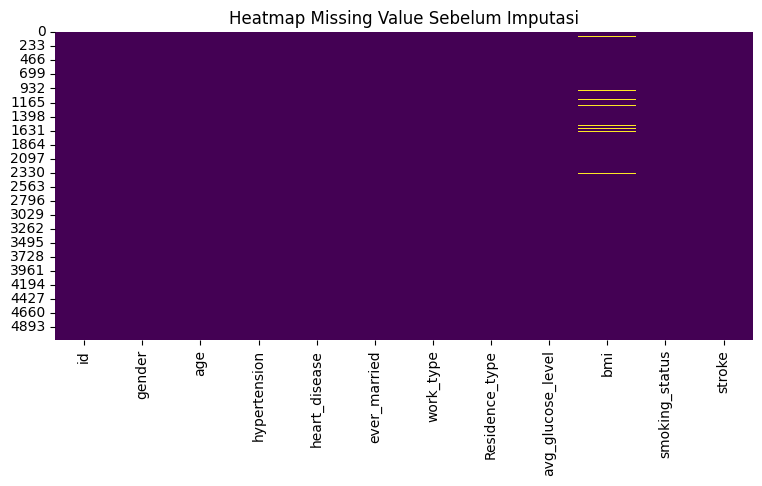

In [11]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap Missing Value Sebelum Imputasi')
plt.show()


**Penjelasan:** Garis kuning pada kolom BMI memperlihatkan 201 sel kosong sebelum ditangani.


### 12. Imputasi Missing Value


In [12]:
# Mengisi missing value BMI dengan median
median_bmi = df['bmi'].median()
df['bmi'] = df['bmi'].fillna(median_bmi)

print('Median BMI:', median_bmi)
print('Sisa Missing Value:', df.isnull().sum().sum())


Median BMI: 28.1
Sisa Missing Value: 0


**Penjelasan:** Nilai kosong pada BMI diisi dengan median (28,10). Data sekarang sudah lengkap tanpa missing value.


### 13. Heatmap Missing Value Setelah Imputasi


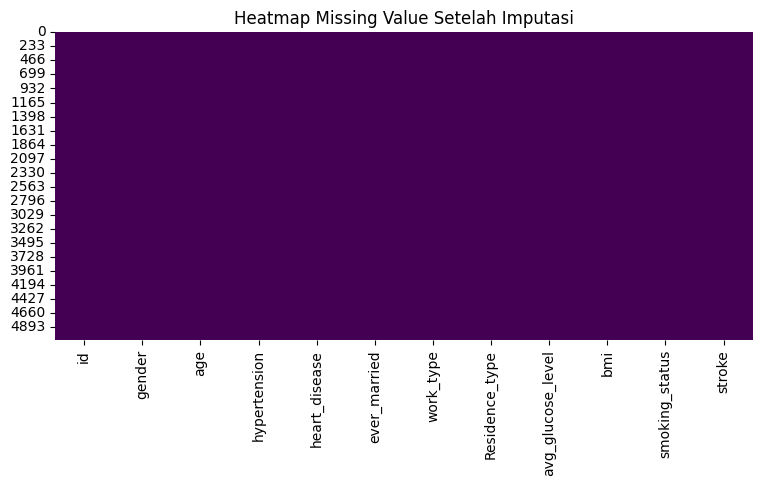

In [13]:
plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap Missing Value Setelah Imputasi')
plt.show()


**Penjelasan:** Heatmap sekarang berwarna ungu solid, membuktikan seluruh data terisi lengkap.


### 14. Cek Data Duplikat


In [14]:
print('Jumlah Baris Duplikat:', df.duplicated().sum())


Jumlah Baris Duplikat: 0


**Penjelasan:** Tidak ada data duplikat (0 duplikat).


### 15. Hapus Data Duplikat


In [15]:
# Menghapus baris data duplikat
df = df.drop_duplicates()
print('Jumlah Duplikat Setelah Dihapus:', df.duplicated().sum())
print('Total Baris Sekarang:', len(df))


Jumlah Duplikat Setelah Dihapus: 0
Total Baris Sekarang: 5110


**Penjelasan:** Fungsi drop_duplicates() dijalankan untuk memastikan data bersih, dan total baris tetap 5.110 data karena tidak ada duplikat.


### 16. Cek Pasien Unik


In [16]:
print('Jumlah Pasien Unik:', df['id'].nunique())


Jumlah Pasien Unik: 5110


**Penjelasan:** Terdapat 5.110 pasien unik, sesuai dengan total baris data.


### 17. Distribusi Kasus Stroke


In [17]:
df['stroke'].value_counts()


stroke
0    4861
1     249
Name: count, dtype: int64

**Penjelasan:** 4.861 pasien tidak stroke (95,13%) dan 249 pasien mengalami stroke (4,87%).


### 18. Pemilihan Atribut untuk Outlier


In [18]:
gula = df['avg_glucose_level']


**Penjelasan:** Kolom kadar gula darah (avg_glucose_level) dipilih untuk analisis outlier.


### 19. Statistik Deskriptif Gula Darah


In [19]:
gula.describe()


count    5110.000000
mean      106.147677
std        45.283560
min        55.120000
25%        77.245000
50%        91.885000
75%       114.090000
max       271.740000
Name: avg_glucose_level, dtype: float64

**Penjelasan:** Rata-rata kadar gula darah adalah 106,15 mg/dL dengan median 91,88 mg/dL dan nilai tertinggi mencapai 271,74 mg/dL.


### 20. Boxplot Gula Darah


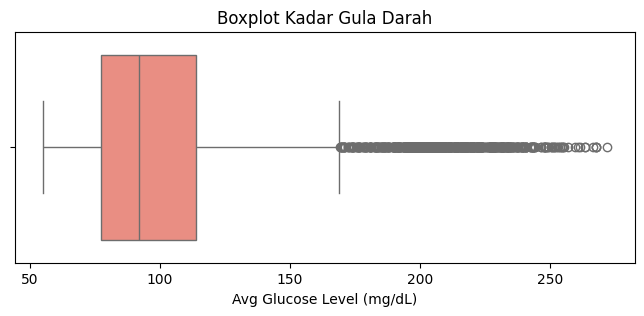

In [20]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=gula, color='salmon')
plt.title('Boxplot Kadar Gula Darah')
plt.xlabel('Avg Glucose Level (mg/dL)')
plt.show()


**Penjelasan:** Boxplot memperlihatkan titik outlier yang cukup banyak di atas 170 mg/dL.


### 21. Hitung Kuartil dan IQR


In [21]:
Q1 = gula.quantile(0.25)
Q3 = gula.quantile(0.75)
IQR = Q3 - Q1

print(f'Q1  : {Q1:.2f}')
print(f'Q3  : {Q3:.2f}')
print(f'IQR : {IQR:.2f}')


Q1  : 77.25
Q3  : 114.09
IQR : 36.84


**Penjelasan:** Nilai Q1 = 77,25, Q3 = 114,09, dan IQR = 36,84.


### 22. Hitung Batas Atas Outlier


In [22]:
batas_atas = Q3 + (1.5 * IQR)
print(f'Batas Atas Outlier: {batas_atas:.2f}')


Batas Atas Outlier: 169.36


**Penjelasan:** Batas atas outlier adalah 169,36 mg/dL. Nilai gula darah di atas 169,36 tergolong pencilan.


### 23. Jumlah Data Outlier


In [23]:
outlier = df[df['avg_glucose_level'] > batas_atas]
print('Jumlah Pasien Outlier:', len(outlier))
print(f'Persentase Outlier: {len(outlier) / len(df) * 100:.2f}%')


Jumlah Pasien Outlier: 627
Persentase Outlier: 12.27%


**Penjelasan:** Ditemukan 627 pasien outlier (12,27%) yang memiliki kadar gula darah sangat tinggi.


### 24. Top 10 Pasien dengan Gula Darah Tertinggi


In [24]:
outlier[['id', 'gender', 'age', 'hypertension', 'avg_glucose_level', 'bmi', 'stroke']].sort_values(by='avg_glucose_level', ascending=False).head(10)


,id,gender,age,hypertension,avg_glucose_level,bmi,stroke
193,69112,Male,68.0,1,271.74,31.1,1
1207,22440,Female,49.0,0,267.76,29.3,0
3088,26267,Female,76.0,0,267.61,27.9,0
4983,10995,Male,76.0,1,267.60,30.5,0
2462,27626,Female,60.0,0,266.59,25.5,0
3393,13155,Female,67.0,1,263.56,26.3,0
135,71279,Female,71.0,0,263.32,38.7,1
4457,50070,Female,62.0,1,261.67,43.0,0
3215,21534,Male,67.0,0,260.85,28.1,0
122,13491,Male,80.0,0,259.63,31.7,1


**Penjelasan:** Pasien dengan gula darah tertinggi berkisar antara 250 hingga 271,74 mg/dL.
